# Занятие 4, пара 1. Края и градиенты

Автор ноутбука - Дуркин Анатолий Альбертович

Старший преподаватель кафедры прикладной математики и компьютерных наук СГУ им. Питирима Сорокина

Замечания, предложения, идеи, вопросы, связь с автором:
- anatoliy.durkin@mail.ru
- Telegram - @AnatoDu

Больше информации и материалов на канале автора: https://t.me/code_matan_ai

**Как проходить тетрадь.** Основные примеры работают независимо от заданий «Ваш ход». Если пока пропускаете задание, пропустите и его ячейку `check(...)`; продолжайте со следующего обычного раздела. Упражнения могут использовать ответы предыдущих упражнений. Сохраните свои попытки в отдельной копии тетради.

## Где на картинке что-то меняется

В прошлый раз мы усредняли соседние пиксели и убирали шум. Сегодня соседние пиксели будем **сравнивать**. Резкий переход яркости может подсказать границу предмета, но может оказаться тенью или полосой на самом предмете. Алгоритм ещё не знает, что именно перед ним.

Пойдём от одного ряда чисел к маленькому окну 3×3, а затем — к изображению. Разберём знак разности, фильтры Собеля и силу градиента. После этого посмотрим, зачем Канни нужны два порога. Всё обязательное вы сможете вычислить на **NumPy и Matplotlib без OpenCV**. Работа готовой реализации Канни показана на сохранённых иллюстрациях; её запуск — отдельное дополнение.

Итог: три самостоятельных упражнения, собственные карты переходов и объяснение, почему граница изображения не равна границе объекта. Если слово «градиент» пока кажется страшным, начнём с обычного вычитания. Оно нас ещё не подводило. Почти.


### Подключим учебные файлы

Следующая ячейка — служебная настройка комплекта. Она находит папку `course_support` у текущей папки или выше и подключает данные и проверки. Её не нужно писать по памяти или менять для задания. `DATA_DIR` — путь к учебным данным, `WORKSPACE_DIR` — корень вашей рабочей папки. `check(номер, ответы)` сравнивает ответ с условиями упражнения, но не выставляет оценку.

Работайте в своей копии и запускайте ячейки сверху вниз. Переменные из другой тетради не нужны. Если поддержку не удалось найти, откройте тетрадь внутри полного комплекта, а не переносите один файл отдельно. Git и интернет для основной работы не нужны.


In [ ]:
import sys
from pathlib import Path

# Одинаковый запуск в репозитории курса и в личном проекте.
for WORKSPACE_DIR in (Path.cwd(), *Path.cwd().parents):
    if (WORKSPACE_DIR / 'course_support' / '__init__.py').is_file():
        break
else:
    raise FileNotFoundError('Откройте тетрадь внутри папки с course_support; нужен весь комплект проекта')

# При переключении курса в том же kernel не оставляем чужую поддержку в памяти.
loaded = sys.modules.get('course_support')
expected = WORKSPACE_DIR / 'course_support' / '__init__.py'
if loaded is not None and Path(loaded.__file__).resolve() != expected.resolve():
    for name in list(sys.modules):
        if name == 'course_support' or name.startswith('course_support.'):
            del sys.modules[name]
sys.path.insert(0, str(WORKSPACE_DIR))
from course_support import SUPPORT_DIR, DATA_DIR
COURSE_DIR = SUPPORT_DIR
# Только упражнения о личном README: в репозитории курса это ещё чистый шаблон.
PROJECT_DIR = WORKSPACE_DIR / 'project_template' if (WORKSPACE_DIR / 'project_template').is_dir() else WORKSPACE_DIR
from course_support.checks import check, summary

PROJECT_DIR


### Рабочие инструменты

NumPy — вычисления над изображениями; Matplotlib — показ. Основной маршрут целиком на CPU, без OpenCV и сети. Готовые картинки Canny ниже подписаны отдельно: это результаты библиотечной демонстрации, а наши карты Собеля считаются здесь.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt


### Вернём смысл свёртки, прежде чем искать края

На предыдущей паре мы двигали окно по изображению, умножали его пиксели на веса ядра и складывали произведения. В каждом положении множество чисел превращалось в **одно число отклика**. Фильтр отвечает на вопрос: «Насколько эта окрестность похожа на сочетание, заданное весами?» Усредняющее ядро реагирует на среднюю яркость, разностное — на изменение яркости.

Для одномерного сигнала математическая свёртка записывается как

$$y[n]=\sum_k x[n-k]h[k].$$

Важна не страшная сумма, а индекс `n-k`: ядро переворачивают и сдвигают относительно сигнала, затем суммируют произведения. В двумерном случае ядро переворачивают по обеим осям. Если приложить веса **без переворота**, получится взаимная корреляция. Именно её выполняет `filter2D`; в задачах фильтрации и нейросетях часто сохраняют слово «свёртка» для этой близкой операции. Мы будем явно говорить, какое соглашение используем.

«Сворачиваем окно в один отклик» — полезный образ для запоминания, а не историческое объяснение происхождения термина. Изображение целиком в один пиксель не исчезает: одному окну соответствует один элемент новой карты.

Проверим разницу на несимметричном ядре. `weights[::-1]` меняет порядок весов. Для симметричного ядра среднего переворот ничего бы не изменил.

In [ ]:
signal_patch = np.array([10, 20, 40], dtype=float)
weights = np.array([-1, 0, 1], dtype=float)
correlation_response = (signal_patch * weights).sum()
flipped_weights = weights[::-1]
convolution_response = (signal_patch * flipped_weights).sum()
print('Без переворота:', correlation_response)
print('С переворотом:', convolution_response)

Получили 30 и −30. Сила перехода та же, знак противоположный. Поэтому нельзя незаметно менять соглашение, когда говорим о направлении края.

| Задача | Что делают веса | Цена/ограничение |
|---|---|---|
| Среднее, гауссово сглаживание | Соседи положительно участвуют; сумма весов 1 | Убирают часть шума вместе с мелкими деталями |
| Производная, например Собель | Сравнивают стороны; сумма весов 0 | Реагируют и на нужный край, и на шум |
| Повышение резкости | Усиливают центр относительно соседей | Возможны ореолы и выход за диапазон яркости |
| Обучаемый фильтр CNN | Веса подбираются по данным и задаче | Один отклик ещё не означает распознавание объекта |

Сглаживание, производная и резкость с фиксированными ядрами — линейные операции до обрезания значений. Медиана и морфология не являются такой взвешенной суммой. Размер окна задаёт масштаб видимых деталей; правило за границей изображения тоже является частью метода.

[Документация OpenCV: filter2D и фильтрация](https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html).

### 1. Самый маленький край

Представим горизонтальный срез изображения. В нём участок постоянной яркости сменяется более светлым. Разность справа и слева — простейшее приближение производной яркости. Она описывает изменение на один пиксель, а не принадлежность к предмету.

Считаем во float: разность может быть отрицательной, а исходный uint8 её не хранит. Это выбор вычислительного типа для производной, не изменение самой сцены.


In [ ]:
line = np.array([20, 20, 20, 100, 100], dtype=float)
left = line[2]
right = line[3]
difference = right - left
print(left, right, difference)


Сравним все соседние пары. У пяти пикселей четыре промежутка, поэтому карта разностей здесь короче исходного ряда на один элемент. Направление сравнения фиксировано: справа минус слева. На постоянном участке ожидаем нули; на скачке — ненулевой отклик.


In [ ]:
differences = []
for i in range(len(line) - 1):
    left = line[i]
    right = line[i + 1]
    differences.append(right - left)
print(differences)


Ноль означает, что яркость соседей одинаковая. Положительная разность — переход от тёмного к светлому при движении вправо; отрицательная — наоборот. Большой модуль означает сильное изменение. Это ещё не ответ «тут человек» или «тут дорога»: пока мы измерили только числа.

**Небольшой опыт, 3 минуты.** Создайте `brighter = line + 30`: NumPy прибавит число к каждому элементу массива. Повторите цикл для `brighter`. Почему разности не изменились? Затем попробуйте `line * 2`. Здесь float и учебные числа: мы не обрезаем значения диапазоном экрана.


### ✏️ Ваш ход — найти оба края полоски

Есть ряд `stripe = np.array([20, 20, 20, 120, 120, 20, 20], dtype=float)`. Создайте список `my_differences` из разностей соседей, двигаясь слева направо. Используйте цикл выше. В выводе назовите, где вход в светлую полоску, а где выход, и почему знаки разные.


In [ ]:
# ✏️ ваш код здесь


In [ ]:
check('04.1.1', my_differences)


**Мой вывод:** замените эту строку своим объяснением результата. Назовите конкретное число, поле или участок изображения, на который опираетесь.


### 2. У края есть направление

Яркость теперь зависит от x и y. В окне ниже она меняется по x, но остаётся постоянной по y. Поэтому производная по x должна быть ненулевой, по y — нулевой. Заметьте: **вертикальная граница** обнаруживается изменением при движении **по горизонтали**. Название оси производной — не направление линии края.


In [ ]:
window = np.array([
    [10, 10, 30],
    [10, 10, 30],
    [10, 10, 30]
], dtype=float)
print(window.shape)
print(window[1, 2])


В блоке 03 мы умножали соседние пиксели на веса и складывали. Сделаем это ещё раз. Ядро Собеля по x берёт отрицательные веса слева и положительные справа. Средняя строка имеет вес 2, соседние — 1: кроме сравнения сторон здесь есть сглаживание в поперечном направлении. Центральный столбец имеет нулевой вес.

Знак `*` между массивами одинаковой формы перемножает соответствующие элементы, а `.sum()` складывает получившиеся значения. Сначала покажем произведения, затем сумму.


In [ ]:
kernel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=float)
products_x = window * kernel_x
print(products_x)
gx = products_x.sum()
print(gx)


Почему именно такие веса? Возьмём разность `[-1, 0, 1]` вдоль x и сглаживание `[1, 2, 1]` вдоль y. Первая строка ядра — одна такая разность, вторая — удвоенная, третья — снова одна. Собель сочетает сравнение сторон с усреднением в поперечном направлении.

На нашем окне перепад 20 повторён в трёх строках с весами 1, 2, 1: получаем 20 × 4 = 80. Это **отклик ненормированного ядра**, не разность только двух пикселей. Сумма весов ядра равна нулю: добавление одной константы ко всем пикселям не создаёт край.

Мы применяем веса без переворота — корреляцию. По этому соглашению свет справа даёт положительный Gx. Для оценки физической производной при шаге 1 пиксель Собель 3×3 часто нормируют на 8: разность берётся через два пикселя, сумма поперечных весов равна 4. Для сравнения наших карт оставим одну и ту же ненормированную шкалу.

Другие операторы решают похожую задачу: Prewitt использует равные поперечные веса, Scharr — другие веса для более точного приближения направления на окне 3×3. Это альтернативы для осмысленного сравнения, а не список функций, которые нужно выучить наизусть.

[Смысл оператора Собеля](https://docs.opencv.org/4.x/d2/d2c/tutorial_sobel_derivatives.html).


Для y сравним верх и низ. Здесь положительное направление y — вниз, потому что так растут номера строк изображения. Снова сначала получим произведения, потом сумму.


In [ ]:
kernel_y = np.array([
    [-1, -2, -1],
    [0, 0, 0],
    [1, 2, 1]
], dtype=float)
products_y = window * kernel_y
print(products_y)
gy = products_y.sum()
print(gy)


Два числа `(gx, gy)` — две составляющие градиента: куда и насколько меняется яркость. Его сила — длина этого вектора. `**2` возводит в квадрат, `np.sqrt` извлекает квадратный корень. Для нашего окна получится 80: по y изменения нет. На диагональном переходе обычно ненулевые обе составляющие.


In [ ]:
squared_length = gx ** 2 + gy ** 2
magnitude = np.sqrt(squared_length)
print(magnitude)


Не перепутайте направление изменения и направление самой границы. У вертикальной светлой полосы яркость меняется **поперёк**, слева направо: откликается Gx. Поэтому «вертикальный край» не означает «большой Gy».

**Опыт перед заданием:** поменяйте окно на три одинаковых столбца, где верхняя строка 10, средняя 10, нижняя 30. Пересчитайте gx/gy. Предскажите результат до запуска. Сохраните оба окна под разными именами, чтобы не потерять исходный пример.


### ✏️ Ваш ход — посчитать Собеля в одном месте

Создайте `my_window` со строками `[10, 10, 50]`, `[10, 10, 50]`, `[10, 10, 50]`. Вычислите `my_gx`, `my_gy` и `my_magnitude`, используя уже определённые ядра. Сначала покажите произведения, затем суммы. В выводе объясните, как ориентирован переход.


In [ ]:
# ✏️ ваш код здесь


In [ ]:
check('04.1.2', my_gx, my_gy, my_magnitude)


**Мой вывод:** замените эту строку своим объяснением результата. Назовите конкретное число, поле или участок изображения, на который опираетесь.


### Модуль говорит «насколько», направление — «куда»

Градиент — вектор $(G_x,G_y)$, указывающий сторону наибольшего роста яркости. Его длина $\sqrt{G_x^2+G_y^2}$ даёт силу изменения. Направление градиента поперечно линии края: у вертикального края вектор горизонтален.

Угол можно найти через `np.arctan2(Gy, Gx)`: эта функция учитывает знаки обеих компонент, в отличие от обычного деления Gy/Gx. Результат в радианах; `np.degrees` переводит его в градусы. На изображении y растёт вниз, поэтому положительные углы здесь поворачивают стрелку в сторону нижней части картинки. При нулевой длине содержательного направления нет.

Повернём прежнее окно на 90° функцией `np.rot90` и проверим, какая компонента ответит теперь. Это обычный пример, он не использует `my_gx` из задания.

In [ ]:
turned_window = np.rot90(window)
turned_gx = (turned_window * kernel_x).sum()
turned_gy = (turned_window * kernel_y).sum()
turned_angle = np.degrees(np.arctan2(turned_gy, turned_gx))
print(turned_window)
print('Gx, Gy:', turned_gx, turned_gy)
print('Угол градиента:', turned_angle)

### 3. Прочитаем картинку без OpenCV

`plt.imread` читает изображение. Для нашего серого PNG вернётся двумерный массив float с яркостями от 0 до 1. Проверим это. `.astype(float)` создаёт массив с выбранным типом чисел; затем умножим его на 255, чтобы работать в знакомой шкале. Это свойство данного файла/способа чтения: не надо автоматически умножать на 255 любое изображение, особенно если оно уже uint8.

Методы массива `.min()` и `.max()` находят наименьшее и наибольшее значения; `.shape` и `.dtype` показывают форму и тип элементов.


In [ ]:
image_path = DATA_DIR / 'edges' / 'scene.png'
loaded = plt.imread(image_path)
print(loaded.shape, loaded.dtype, loaded.min(), loaded.max())
image = loaded.astype(float) * 255
print(image.min(), image.max())


Сцена специально синтетическая: прямоугольник, круг, слабая горизонтальная полоска и шум. Мы знаем, где объекты, поэтому можем проверить отклики на фоне и на границах отдельно. Алгоритм этих названий не знает. float нужен для отрицательных значений и откликов больше 255.


Сравниваем яркости в общей шкале 0…255. Автоматическая растяжка каждой картинки по её минимуму и максимуму могла бы скрыть различие контраста. Шкала показа не меняет исходные числа.


In [ ]:
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title('Исходная учебная сцена')
plt.colorbar()
plt.show()


Чтобы приложить окно к краю изображения, добавим рамку. `np.pad(image, 1, mode='reflect')` добавляет один пиксель с каждой стороны, отражая соседние значения. Это явное правило для границ. Без него окно у края выходило бы за массив. Срез `y:y+3, x:x+3` берёт три строки и три столбца; правая граница среза не включается.


In [ ]:
padded = np.pad(image, 1, mode='reflect')
print(image.shape, padded.shape)
y = 50
x = 25
patch = padded[y:y+3, x:x+3]
print(patch)
products = patch * kernel_x
print(products.sum())


### 4. Построим карту откликов

Каждому положению окна соответствует один выходной пиксель. Ниже `correlate3` реализует именно это правило с шагом 1 и отражением у края. Весовые произведения суммируются по исходному окну; уже рассчитанные выходные пиксели не участвуют в соседнем расчёте. Поэтому порядок обхода не меняет результат.

Функция ограничена ядром 3×3 и серым изображением. Это прозрачная учебная реализация: она позволяет проверить смысл формулы, но Python-циклы не стоит брать для обработки большого видео.


In [ ]:
def correlate3(source, kernel):
    height, width = source.shape
    padded = np.pad(source, 1, mode='reflect')
    result = np.zeros_like(source, dtype=float)
    for y in range(height):
        for x in range(width):
            patch = padded[y:y+3, x:x+3]
            products = patch * kernel
            result[y, x] = products.sum()
    return result

map_x = correlate3(image, kernel_x)
map_y = correlate3(image, kernel_y)
strength = np.sqrt(map_x ** 2 + map_y ** 2)
print(strength.shape)


Знак Gx/Gy нужен для направления, но на сером изображении отрицательные значения неудобно сравнивать с положительными. `np.abs` берёт модуль **для показа**; исходные карты сохраняем. Значения Собеля могут быть больше 255, поэтому шкалу силы выберем отдельно. `vmax=400` означает: всё сильнее будет показано белым; сами числа не обрезаются.


In [ ]:
absolute_x = np.abs(map_x)
plt.imshow(absolute_x, cmap='gray', vmin=0, vmax=400)
plt.title('Сила изменения по x')
plt.colorbar()
plt.show()

absolute_y = np.abs(map_y)
plt.imshow(absolute_y, cmap='gray', vmin=0, vmax=400)
plt.title('Сила изменения по y')
plt.colorbar()
plt.show()

plt.imshow(strength, cmap='gray', vmin=0, vmax=400)
plt.title('Общая сила градиента')
plt.colorbar()
plt.show()


**Самостоятельный опыт, 8–10 минут.** Найдите на картах левую сторону прямоугольника и его верхнюю сторону. Какая карта сильнее реагирует на каждую? Затем создайте `shifted = image + 20`, рассчитайте обе карты и силу той же функцией. Сравните с исходными. Для численного сравнения можно вычесть массивы, взять `np.abs`, затем `.max()` — максимальное расхождение. Объясните, почему общий сдвиг яркости не должен усиливать край, если мы не обрезаем значения. Резерв: повторите с `image * 1.5`.

Запишите не только «стало лучше», а конкретно: какой участок, какая карта, что изменили и что наблюдали. Не надо узнавать предметы там, где алгоритм лишь сравнил соседей.


### Шум тоже меняется — производная об этом честно сообщает

Если шум добавил к одному пикселю +10, а к соседу −10, разность получит добавку 20. Поэтому детектор краёв без сглаживания может старательно обнаружить то, чего на предмете не было. Но сильное сглаживание размоет и тонкую нужную линию.

Сравним одну сцену при одинаковом масштабе карты. Сначала сгладим её маленьким биномиальным ядром из прошлого блока, затем снова вычислим обе компоненты. Это приближение гауссова сглаживания, не реализация всей цепочки Canny.

In [ ]:
smooth_kernel = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=float) / 16
smoothed_image = correlate3(image, smooth_kernel)
smooth_x = correlate3(smoothed_image, kernel_x)
smooth_y = correlate3(smoothed_image, kernel_y)
smooth_strength = np.sqrt(smooth_x ** 2 + smooth_y ** 2)
plt.imshow(smooth_strength, cmap='gray', vmin=0, vmax=400)
plt.title('Градиент после сглаживания')
plt.colorbar()
plt.show()
print('Средний отклик на участке фона до:', strength[10:30, 10:30].mean())
print('На том же участке после:', smooth_strength[10:30, 10:30].mean())

**Опыт на 6–8 минут.** Участок `[10:30, 10:30]` выбран на известном фоне синтетической сцены. Падение отклика там полезно, но не доказывает сохранение всех нужных краёв. Найдите слабую горизонтальную линию: что с ней произошло? Затем повторно сгладьте `smoothed_image` и сравните. Для своих вариантов используйте отдельные имена; дальнейший код их не требует.

Зафиксируйте компромисс: «при таких параметрах исчезло …, но потерялось …». Слово «лучше» без указания задачи здесь слишком удобное.

### 5. Почему одной силы градиента мало

Вокруг границы на карте часто получается широкая светлая полоса, а на шуме — мелкие отклики. Алгоритм **Канни (Canny)** решает несколько задач последовательно:

1. Сглаживание уменьшает мелкий шум. В нашем сравнении перед Canny отдельно применено гауссово сглаживание.
2. По градиенту оценивается сила и направление перехода.
3. Подавление немаксимумов оставляет локальные максимумы **вдоль направления градиента**, чтобы сделать край тоньше.
4. Два порога разделяют сильные, слабые и слишком слабые отклики. Слабые сохраняются, если соединены цепочкой с сильными.

Это описание алгоритма, а не обещание написать его целиком за десять минут. Наш Собель выше уже вычислен своими руками. Для Канни сейчас разберём идею связи на маленьком примере и рассмотрим результат библиотечной реализации.


### Зачем подавлять немаксимумы

Возьмём срез силы градиента **поперёк** одного края. Вместо одного пикселя видим холм `[0, 30, 90, 60, 10, 0]`. Порог 20 оставил бы три пикселя. Подавление немаксимумов оставляет вершину холма: сравнивает отклик с соседями вдоль направления градиента. Это позволяет уточнить положение края.

Для двумерной картинки надо использовать направление в каждой точке; поиск максимума всей строки был бы неверным. Ниже только один заранее выбранный срез и одна проверка вершины, не готовый Canny.

In [ ]:
profile = np.array([0, 30, 90, 60, 10, 0])
peak = 2
is_local_maximum = (profile[peak] > profile[peak - 1]) and (profile[peak] > profile[peak + 1])
print('Отклики выше порога 20:', profile > 20)
print('Позиция 2 — локальный максимум:', is_local_maximum)

**Сохранённая демонстрация OpenCV — доступна без установки.** Один исходник, одинаковое предварительное сглаживание 5×5, sigma=1; меняется только пара порогов. Использовано `L2gradient=True`, то есть евклидова сила градиента. Это заранее вычисленные результаты, не результат запуска ваших ячеек.

Сначала найдите слабую горизонтальную полоску и шумовой фон. Сравните три варианта: что потеряли при высоких порогах, что добавилось при низких? Не выбирайте лучший вариант по количеству белых пикселей: сформулируйте, какой объект хотели найти.

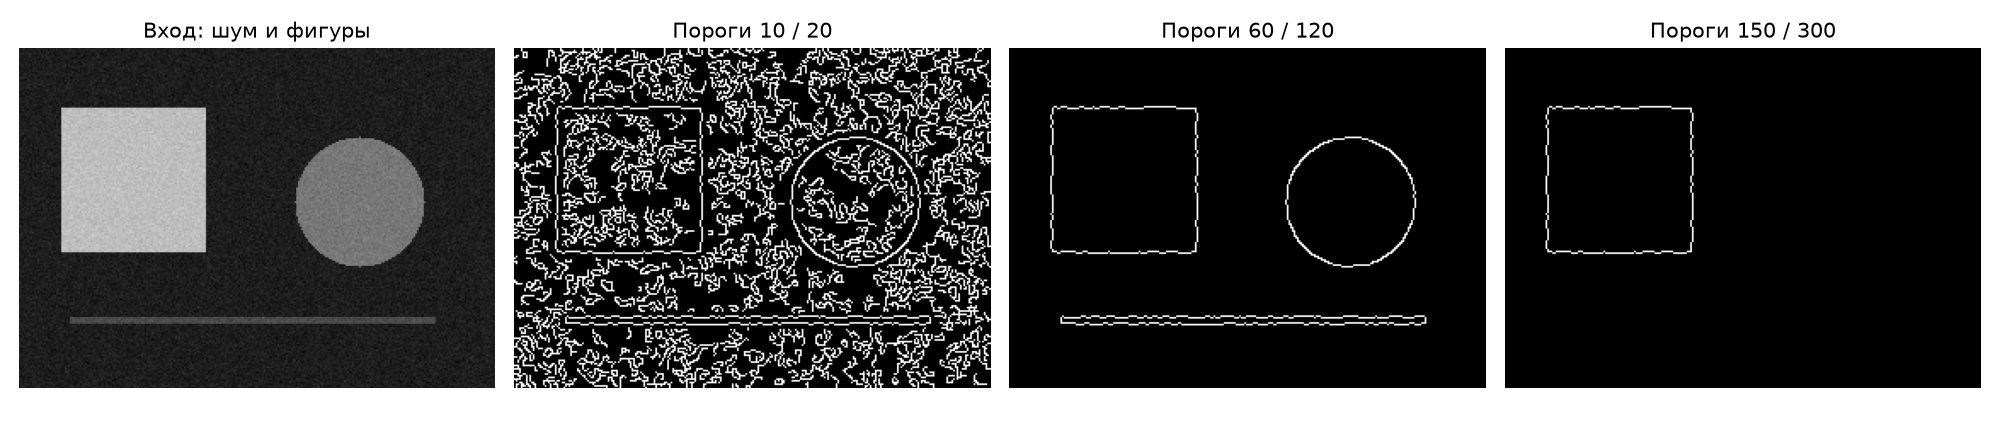


### 6. Два порога на одномерной цепочке

Пока забудем про двумерные картинки и оставим ряд откликов. Верхний порог — 80, нижний — 40. Сильный отклик больше 80, слабый больше 40, но не больше 80. Для простоты в числах нет значений ровно на порогах. NumPy сравнивает каждый элемент и создаёт маску True/False.


In [ ]:
responses = np.array([0, 100, 60, 50, 0, 55, 0])
strong = responses > 80
candidates = responses > 40
print(strong)
print(candidates)


Сильная позиция 1 сохраняется. Позиция 2 с ней соседствует, поэтому тоже сохраняется. Позиция 3 связана через позицию 2 — цепочка продолжается. А позиция 5 отделена нулём: одного превышения нижнего порога недостаточно.

Это **учебная одномерная модель связи**, не полная реализация Канни: здесь нет подавления немаксимумов и поиска связности по двумерному изображению. Модель нужна, чтобы понять, зачем два порога, а не выдать короткую маску за готовый детектор.


### ✏️ Ваш ход — сохранить связанную цепочку

Запишите список `kept` из семи значений True/False для ряда `responses`. Здесь ответ можно записать вручную: проверяем рассуждение о связности. В пояснении обязательно разберите позиции 3 и 5. Затем придумайте изменение одного числа, после которого позиция 5 тоже будет сохранена, и объясните почему.


In [ ]:
# ✏️ ваш код здесь


In [ ]:
check('04.1.3', kept)


**Мой вывод:** замените эту строку своим объяснением результата. Назовите конкретное число, поле или участок изображения, на который опираетесь.


### Дополнительно: тот же Canny на компьютере с OpenCV

Этот фрагмент можно прочитать без запуска. `GaussianBlur` принимает изображение, размер окна и sigma; `Canny` — изображение и два порога. Для этих функций здесь нужен `uint8`, поэтому отдельно преобразуем знакомый диапазон 0…255. `np.clip` ограничивает значения перед преобразованием, `.astype(np.uint8)` меняет тип. При отсутствии OpenCV ничего устанавливать во время пары не нужно.

```python
import cv2
clipped = np.clip(image, 0, 255)
image_u8 = clipped.astype(np.uint8)
smoothed = cv2.GaussianBlur(image_u8, (5, 5), 1)
edges = cv2.Canny(smoothed, 60, 120, L2gradient=True)
plt.imshow(edges, cmap='gray', vmin=0, vmax=255)
plt.show()
```

[Описание Canny в OpenCV](https://docs.opencv.org/4.x/da/d22/tutorial_py_canny.html). Пара порогов зависит от масштаба яркости, шума, сглаживания и задачи; единственных «правильных порогов для всех картинок» нет.

### Что осталось у нас

Сохраните тетрадь с тремя ответами и наблюдениями по картам. Своими словами объясните разницу между яркостью, её изменением и объектом. В следующей паре превратим изображение в маску, исправим мелкие дефекты и попробуем измерить предмет по эталону.
